# FourCasters : prévision d'un dépassement hydrologique à J+1

Projet collectif réalisé dans le cadre de la formation **Data Analyst de la Wild Code School**.

Ce notebook présente l'exploration des données, l'entraînement et l'évaluation d'une régression logistique. Le modèle estime si la hauteur maximale journalière d'une station atteindra ou dépassera son **P95 historique à J+1**. Les nouveaux franchissements sont évalués séparément : station sous le seuil à J, puis au seuil ou au-dessus à J+1.

Les sorties conservées correspondent à un jeu couvrant le **01/01/2000 au 30/09/2026** : **1 796 900 lignes et 247 stations**. Elles documentent le retest référencé au **07/10/2026** dans le README du projet.

> **Périmètre des résultats :** les sorties précèdent la correction de `pluie_3j` du **11/10/2026**. Cette mise en forme conserve le code et les sorties ; aucun entraînement ni calcul de métriques supplémentaire n'a été exécuté.

## 1. Accès aux données

Le notebook est prévu pour **Google Colab**, avec authentification Google et accès BigQuery au projet `projet-les-fourcasters`. Il utilise pandas, scikit-learn, matplotlib, seaborn et joblib, disponibles dans l'environnement de travail Colab à vérifier avant une nouvelle exécution.

La requête lit `marts.ml_features`, construite par les modèles SQL/dbt de FourCasters. Les graphiques et sorties enregistrés peuvent être consultés directement sur GitHub. Pour réexécuter le notebook, il faut les droits BigQuery nécessaires ; la lecture peut entraîner des coûts. La table étant actualisée, une nouvelle exécution peut produire des volumes et résultats différents de cette photographie historique.

In [1]:
from google.colab import auth
auth.authenticate_user()

In [2]:
from google.cloud import bigquery
import pandas as pd

project_id = "projet-les-fourcasters"

client = bigquery.Client(project=project_id)

In [3]:
query = """
SELECT *
FROM `projet-les-fourcasters.marts.ml_features`
"""

df = client.query(query).to_dataframe()

## 2. Exploration et qualité du jeu

Inspection du volume, des colonnes, des distributions et des valeurs manquantes. Le jeu complet conserve les lignes sans observation future : elles servent à l'inférence et doivent être exclues de l'entraînement.

In [4]:
df.shape

(1796900, 12)

In [5]:
df.head()

,date,code_station,code_insee,code_departement,position_p95,variation_position_1j,pluie_j,pluie_3j,humidite_sol,mois,depasse_p95_j,target_j1
0,2014-01-24,A061005051,67482,67,-0.871895,0.047059,3.5,5.2,0.473,1,0,0
1,2024-01-30,A061005051,67482,67,-0.440523,-0.086275,0.0,0.0,0.438,1,0,0
2,2026-01-23,A061005051,67482,67,-1.091503,-0.007843,0.8,0.8,0.447,1,0,0
3,2022-01-24,A061005051,67482,67,-1.022222,0.032680,0.0,0.3,0.441,1,0,0
4,2025-01-17,A061005051,67482,67,-0.660131,0.001307,0.0,0.0,0.425,1,0,0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1796900 entries, 0 to 1796899
Data columns (total 12 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   date                   dbdate 
 1   code_station           object 
 2   code_insee             object 
 3   code_departement       object 
 4   position_p95           float64
 5   variation_position_1j  float64
 6   pluie_j                float64
 7   pluie_3j               float64
 8   humidite_sol           float64
 9   mois                   Int64  
 10  depasse_p95_j          Int64  
 11  target_j1              Int64  
dtypes: Int64(3), dbdate(1), float64(5), object(3)
memory usage: 169.7+ MB


In [7]:
df["date"] = pd.to_datetime(df["date"])

In [8]:
df.describe()

,date,position_p95,variation_position_1j,pluie_j,pluie_3j,humidite_sol,mois,depasse_p95_j,target_j1
count,1796900,1.796900e+06,1.795122e+06,1.796900e+06,1.796900e+06,1.796900e+06,1796900.0,1796900.0,1795122.0
mean,2014-02-18 08:47:46.376536832,-1.196622e+00,-1.695826e-03,2.341032e+00,7.022324e+00,3.338125e-01,6.46439,0.052156,0.052097
min,2000-01-01 00:00:00,-4.686346e+02,-2.807600e+03,0.000000e+00,0.000000e+00,9.700000e-02,1.0,0.0,0.0
25%,2007-11-24 00:00:00,-1.225225e+00,-5.315615e-02,0.000000e+00,1.000000e-01,2.820000e-01,3.0,0.0,0.0
50%,2014-07-13 00:00:00,-8.141593e-01,-8.227375e-03,1.000000e-01,2.800000e+00,3.530000e-01,6.0,0.0,0.0
75%,2020-07-23 00:00:00,-4.898785e-01,2.347826e-02,2.400000e+00,1.020000e+01,3.910000e-01,9.0,0.0,0.0
max,2026-09-30 00:00:00,2.844400e+03,2.789600e+03,1.586000e+02,2.635000e+02,6.860000e-01,12.0,1.0,1.0
std,NaN,9.522269e+00,4.397519e+00,4.918763e+00,1.029195e+01,8.238975e-02,3.438462,0.222343,0.222222


In [9]:
df.isna().sum()

,0
date,0
code_station,0
code_insee,0
code_departement,0
position_p95,0
variation_position_1j,1778
pluie_j,0
pluie_3j,0
humidite_sol,0
mois,0


## 3. Séparation chronologique

Seules les lignes avec `target_j1` renseignée sont utilisées pour apprendre et évaluer le modèle. Cela conserve **1 795 122 lignes** et écarte **1 778 lignes sans cible** dans l'état enregistré.

- Entraînement : dates **avant le 01/01/2023**, soit **1 528 444 lignes**.
- Test : dates **à partir du 01/01/2023**, soit **266 678 lignes**.

Cette séparation conserve l'ordre temporel. Elle ne supprime pas le risque lié aux seuils historiques calculés en amont sur l'ensemble de l'historique, expliqué dans les limites finales.

In [10]:
df["date"] = pd.to_datetime(df["date"])

df_model = df[df["target_j1"].notna()].copy()

print("Dataset complet :", df.shape)
print("Dataset avec cible :", df_model.shape)
print("Lignes sans cible :", df["target_j1"].isna().sum())
print("Stations :", df["code_station"].nunique())
print("Date min :", df["date"].min())
print("Date max :", df["date"].max())

train = df_model[df_model["date"] < "2023-01-01"].copy()
test = df_model[df_model["date"] >= "2023-01-01"].copy()

Dataset complet : (1796900, 12)
Dataset avec cible : (1795122, 12)
Lignes sans cible : 1778
Stations : 247
Date min : 2000-01-01 00:00:00
Date max : 2026-09-30 00:00:00


In [11]:
print("Train :", train.shape)
print("Test :", test.shape)

print("Part train :", round(len(train) / len(df_model) * 100, 2), "%")
print("Part test :", round(len(test) / len(df_model) * 100, 2), "%")

Train : (1528444, 12)
Test : (266678, 12)
Part train : 85.14 %
Part test : 14.86 %


In [12]:
print("\nTrain :")
print(train["target_j1"].value_counts(normalize=True) * 100)

print("\nTest :")
print(test["target_j1"].value_counts(normalize=True) * 100)


Train :
target_j1
0    94.984115
1     5.015885
Name: proportion, dtype: Float64

Test :
target_j1
0    93.679644
1     6.320356
Name: proportion, dtype: Float64


In [13]:
train["target_j1"].value_counts()

,count
target_j1,
0,1451779
1,76665


## 4. Déséquilibre de la cible et exploration des variables

Dans l'entraînement enregistré, environ **5,02 %** des lignes ont une cible positive. Les graphiques permettent d'observer ce déséquilibre, les distributions et les corrélations. Une corrélation ne démontre pas une relation causale.

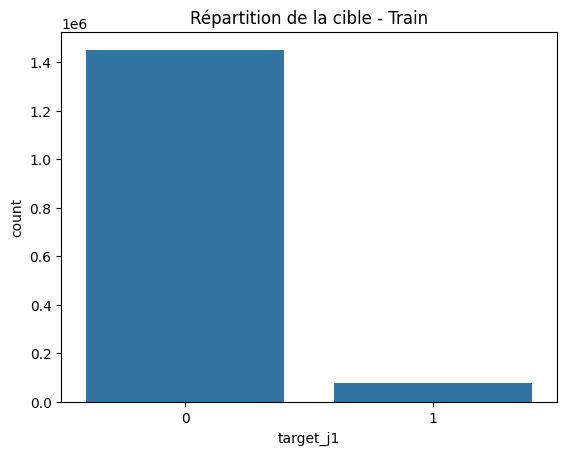

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=train, x="target_j1")
plt.title("Répartition de la cible - Train")
plt.show()

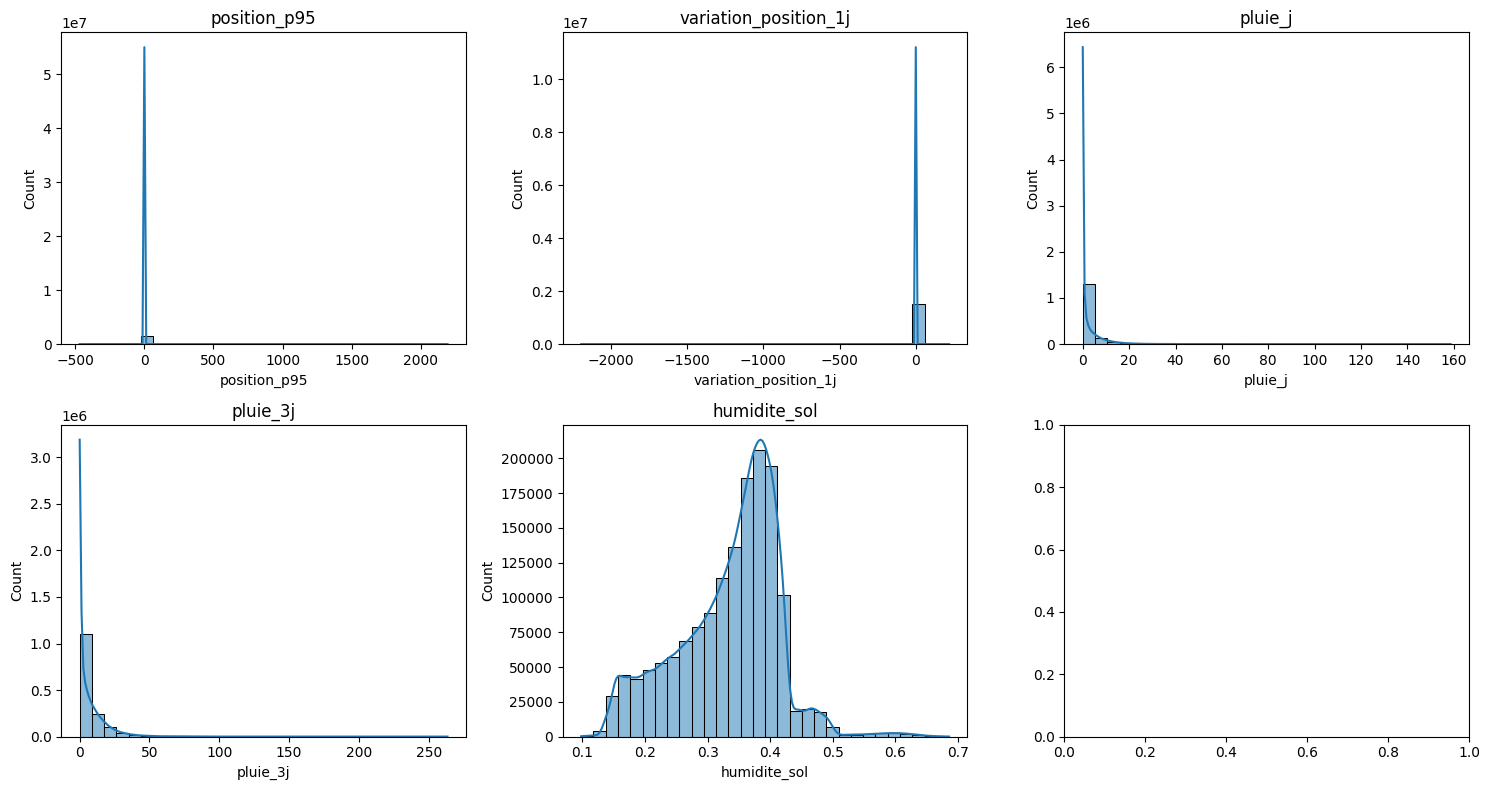

In [15]:
features_numeriques = [
    "position_p95",
    "variation_position_1j",
    "pluie_j",
    "pluie_3j",
    "humidite_sol"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, col in enumerate(features_numeriques):
    sns.histplot(train[col], bins=30, kde=True, ax=axes[i//3][i%3])
    axes[i//3][i%3].set_title(col)

plt.tight_layout()
plt.show()

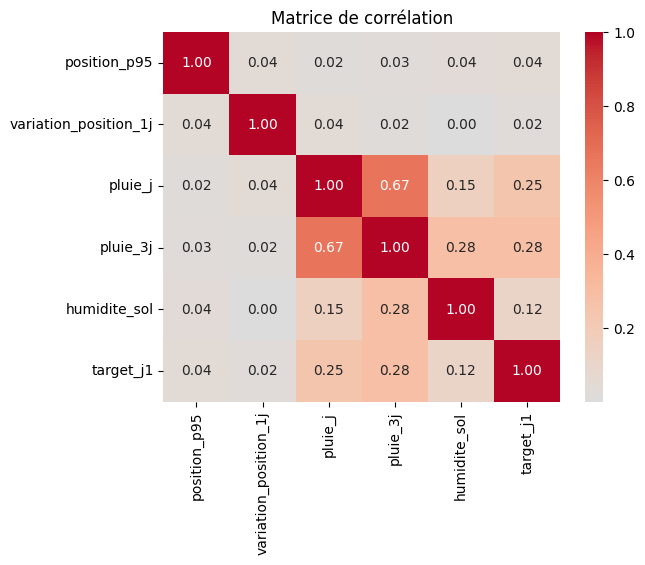

In [16]:
correlation = train[
    [
        "position_p95",
        "variation_position_1j",
        "pluie_j",
        "pluie_3j",
        "humidite_sol",
        "target_j1"
    ]
].corr()

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Matrice de corrélation")
plt.show()

## 5. Les cinq variables du classifieur

| Variable | Signification |
| --- | --- |
| `position_p95` | Position du niveau à J : `(hauteur_j - P95) / (P99 - P90)` |
| `variation_position_1j` | Variation de cette position entre J−1 et J, lorsque les jours sont consécutifs |
| `pluie_j` | Pluie journalière de la commune de la station |
| `pluie_3j` | Cumul de pluie sur la fenêtre J−2 à J |
| `humidite_sol` | Humidité du sol à 7–28 cm |

`mois` figure dans le jeu mais n'entre pas dans le classifieur. `target_j1` est la cible à prédire. `depasse_p95_j` sert à la comparaison avec la persistance et au filtrage des nouveaux franchissements ; il n'est pas ajouté aux cinq entrées.

Depuis la correction SQL du 11/10/2026, le cumul de pluie exige trois dates distinctes et renseignées. Les sorties de ce notebook conservent l'état antérieur à cette correction.

In [17]:
features = [
    "position_p95",
    "variation_position_1j",
    "pluie_j",
    "pluie_3j",
    "humidite_sol"
]

X_train = train[features]
y_train = train["target_j1"].astype(int)

X_test = test[features]
y_test = test["target_j1"].astype(int)

print("X_train :", X_train.shape)
print("X_test :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test :", y_test.shape)

X_train : (1528444, 5)
X_test : (266678, 5)
y_train : (1528444,)
y_test : (266678,)


## 6. Entraînement de la régression logistique

Le pipeline applique successivement :

1. **Imputation médiane** des valeurs manquantes.
2. **Standardisation** des cinq variables.
3. **Régression logistique** avec `class_weight="balanced"`.

L'imputation et la standardisation sont ajustées uniquement sur l'entraînement par `pipeline.fit`. La pondération tient compte de la rareté des dépassements. Le modèle fournit une base simple et rapide, avec des coefficients interprétables ; sa sensibilité s'accompagne de fausses détections.

In [18]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

In [19]:
pipeline.fit(X_train, y_train)

y_pred = pipeline.predict(X_test)

from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, digits=3))

              precision    recall  f1-score   support

           0      0.991     0.878     0.931    249823
           1      0.326     0.877     0.476     16855

    accuracy                          0.878    266678
   macro avg      0.659     0.877     0.703    266678
weighted avg      0.949     0.878     0.902    266678



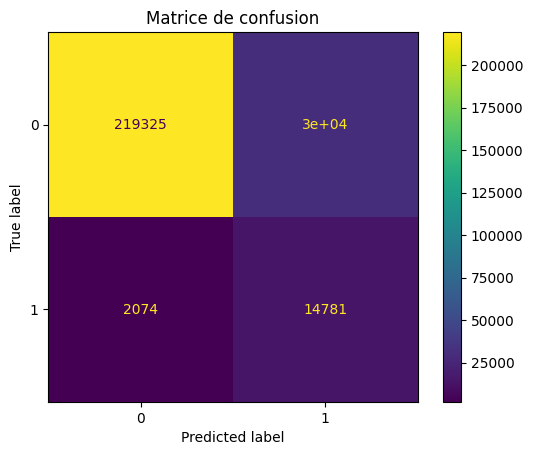

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1]
)

disp.plot()
plt.title("Matrice de confusion")
plt.show()

## 7. Comparaison avec la persistance

La règle de persistance prédit que l'état observé à J restera identique à J+1. Elle constitue un repère utile pour les épisodes déjà en cours. Sur les jours sous le P95 à J, cette règle prédit toujours zéro et ne détecte donc aucun nouveau franchissement.

In [21]:
from sklearn.metrics import classification_report

y_pred_persistance = test["depasse_p95_j"].astype(int)

print("=== Baseline persistance ===")
print(classification_report(y_test, y_pred_persistance, digits=3))

=== Baseline persistance ===
              precision    recall  f1-score   support

           0      0.980     0.980     0.980    249823
           1      0.699     0.699     0.699     16855

    accuracy                          0.962    266678
   macro avg      0.839     0.839     0.839    266678
weighted avg      0.962     0.962     0.962    266678



## 8. Évaluation des nouveaux franchissements

L'évaluation suivante porte uniquement sur les stations **sous le P95 à J**. Les positifs sont les passages au seuil ou au-dessus à J+1.

- **Rappel** : part des franchissements réels détectés.
- **Précision** : part des détections positives correspondant à un franchissement réel.
- **F1** : moyenne harmonique de la précision et du rappel.

Le comptage exact enregistré donne **3 007 détections sur 5 080 franchissements**, soit **59,19 % de rappel**. Ce périmètre correspond au KPI arrondi à 59 % dans le dashboard.

In [22]:
masque_declenchement = test["depasse_p95_j"] == 0

y_test_declenchement = y_test[masque_declenchement]
y_pred_declenchement = y_pred[masque_declenchement]

print(
    classification_report(
        y_test_declenchement,
        y_pred_declenchement,
        digits=3
    )
)

# Comptage exact des nouveaux franchissements : sous P95 à J, au-dessus à J+1
masque_nouveau = (
    (test["depasse_p95_j"] == 0)
    & (test["target_j1"] == 1)
).to_numpy()

nb_nouveaux = int(masque_nouveau.sum())
nb_detectes = int(((y_pred == 1) & masque_nouveau).sum())
rappel_nouveaux = nb_detectes / nb_nouveaux

print("Nouveaux franchissements :", nb_nouveaux)
print("Détectés :", nb_detectes)
print("Rappel nouveaux franchissements :", round(rappel_nouveaux * 100, 2), "%")

              precision    recall  f1-score   support

           0      0.991     0.896     0.941    244752
           1      0.106     0.592     0.179      5080

    accuracy                          0.890    249832
   macro avg      0.548     0.744     0.560    249832
weighted avg      0.973     0.890     0.926    249832

Nouveaux franchissements : 5080
Détectés : 3007
Rappel nouveaux franchissements : 59.19 %


## 9. Comparaison entraînement / test

Les rapports suivants permettent de comparer les performances sur les deux périodes. Ces résultats restent rétrospectifs et doivent être lus avec les limites de construction des variables et des seuils.

In [23]:
y_pred_train = pipeline.predict(X_train)

print("=== TRAIN ===")
print(classification_report(y_train, y_pred_train, digits=3))

print("=== TEST ===")
print(classification_report(y_test, y_pred, digits=3))

=== TRAIN ===
              precision    recall  f1-score   support

           0      0.991     0.885     0.935   1451779
           1      0.281     0.854     0.423     76665

    accuracy                          0.883   1528444
   macro avg      0.636     0.869     0.679   1528444
weighted avg      0.956     0.883     0.909   1528444

=== TEST ===
              precision    recall  f1-score   support

           0      0.991     0.878     0.931    249823
           1      0.326     0.877     0.476     16855

    accuracy                          0.878    266678
   macro avg      0.659     0.877     0.703    266678
weighted avg      0.949     0.878     0.902    266678



## 10. Random Forest : code de comparaison antérieure

Une comparaison avec Random Forest a été effectuée dans le notebook de travail initial `ML_Fourcasters(1).ipynb`, sur `marts.ml_dataset_v1` et un jeu arrêté au **17/09/2026**.

Les trois cellules de comparaison ci-dessous sont conservées, mais **elles ne sont pas exécutées dans le présent retest et ne contiennent aucune sortie enregistrée**. Les chiffres de l'expérimentation antérieure ne sont donc pas présentés comme des résultats du jeu à 1 796 900 lignes. Ils ne permettent pas d'établir une comparaison actualisée sur ce retest.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train.fillna(X_train.median()), y_train)

y_pred_rf = rf.predict(
    X_test.fillna(X_train.median())
)

print(classification_report(y_test, y_pred_rf, digits=3))

In [ ]:
masque_declenchement = test["depasse_p95_j"] == 0

y_test_declenchement = y_test[masque_declenchement]
y_pred_rf_declenchement = y_pred_rf[masque_declenchement]

print(
    classification_report(
        y_test_declenchement,
        y_pred_rf_declenchement,
        digits=3
    )
)

nb_detectes_rf = int(((y_pred_rf == 1) & masque_nouveau).sum())

print("Détectés RF :", nb_detectes_rf)
print(
    "Rappel nouveaux franchissements RF :",
    round(nb_detectes_rf / nb_nouveaux * 100, 2),
    "%"
)

In [ ]:
y_pred_rf_train = rf.predict(
    X_train.fillna(X_train.median())
)

print("=== TRAIN RF ===")
print(classification_report(y_train, y_pred_rf_train, digits=3))

print("=== TEST RF ===")
print(classification_report(y_test, y_pred_rf, digits=3))

## 11. Résultats enregistrés et choix du modèle

### Évaluation globale sur la classe positive

Ce périmètre inclut les nouveaux franchissements et les épisodes déjà au-dessus du seuil à J.

| Modèle | Précision | Rappel | F1 |
| --- | ---: | ---: | ---: |
| Régression logistique | 32,6 % | 87,7 % | 47,6 % |
| Persistance | 69,9 % | 69,9 % | 69,9 % |

### Nouveaux franchissements uniquement

| Modèle | Précision | Rappel | F1 |
| --- | ---: | ---: | ---: |
| Régression logistique | 10,6 % | **59,19 %** | 17,9 % |

Le rappel est calculé exactement avec **3 007 franchissements détectés sur 5 080** ; la précision et le F1 sont arrondis d'après le rapport enregistré. Le rappel global de 87,7 % et le rappel de 59,19 % décrivent deux périmètres différents.

La régression logistique est retenue pour le projet : elle détecte une partie des nouveaux franchissements, avec un pipeline simple et interprétable. La faible précision indique toutefois de nombreux faux positifs. Les comparaisons antérieures avec Random Forest avaient contribué à ce choix ; elles ne sont pas réévaluées dans ce retest. Les résultats obtenus avec les réglages testés ne démontrent pas une supériorité générale sur tous les autres modèles ou seuils de décision.

### Limites et vérifications nécessaires

- **Seuils historiques :** les P90/P95/P99 du modèle dbt sont calculés sur l'ensemble de l'historique disponible. Une évaluation prospective doit calculer les seuils uniquement avec le passé afin de limiter l'utilisation d'information future.
- **Interprétation :** atteindre le P95 est un dépassement statistique hydrologique. Cela ne démontre pas une inondation ou des dommages.
- **Faux positifs :** la précision de 10,6 % impose de valider l'usage métier et le seuil de décision avant une utilisation opérationnelle.
- **Scores :** aucune calibration des probabilités ni PR-AUC n'est démontrée par les sorties de ce notebook.
- **Correction des données :** les résultats précèdent la correction de `pluie_3j` du 11/10/2026. Le jeu corrigé peut avoir moins de lignes ou une couverture différente ; ces métriques ne lui sont pas attribuées.
- **Reproduction historique :** la table BigQuery évolue et le jeu de ce retest n'est pas fourni comme export figé. Les cellules Random Forest, coefficients, export et versions n'ont pas été exécutées dans l'état conservé.

Pour actualiser les résultats : construire et contrôler `ml_features` dans BigQuery, réexécuter l'évaluation chronologique, puis mettre à jour ensemble les sorties, les conclusions et les chiffres du README. Pour une validation prospective, reconstruire également les seuils avec les seules observations passées.

## 12. Coefficients du modèle

Cette cellule permet d'inspecter les coefficients après standardisation. Leur signe indique le sens de l'association dans le modèle, à autres variables constantes ; il ne démontre pas une causalité. Cette cellule n'a pas de sortie enregistrée dans le retest fourni.

In [ ]:
import pandas as pd

coefs = pd.Series(
    pipeline.named_steps["model"].coef_[0],
    index=features
).sort_values(key=abs, ascending=False)

print(coefs)

## 13. Export du pipeline

La cellule suivante permet de sauvegarder le pipeline avec joblib. **Elle n'a pas été exécutée dans le retest fourni.** Ce notebook documente l'entraînement et l'évaluation ; il ne prouve pas que le fichier `.pkl` déjà présent dans le dépôt provient de cette exécution précise.

L'export et l'affichage des versions sont conservés pour une éventuelle réexécution. La mise en forme du notebook ne remplace aucun modèle sauvegardé.

In [ ]:
import joblib

joblib.dump(
    pipeline,
    "fourcasters_logistic_regression.pkl"
)

In [ ]:
import sklearn
import joblib
import sys

print("Python :", sys.version)
print("scikit-learn :", sklearn.__version__)
print("joblib :", joblib.__version__)